# CFAR candidates + CNN classifier: cross-validated training and evaluation

Implements [`PLAN.md`](PLAN.md) (pre-registered, with the additions fixed before any model was trained). Reads only what `build_cache_and_chips.ipynb` saved in Google Drive, so **no scene is downloaded**.

**Question:** does a small CNN that classifies OS-CFAR candidates (T = 5.0 dB) beat the best single-stage detector, Hollow OS-CFAR at T = 8.1 dB (pooled F1 70.7% on the same 49 scenes)?

**Primary result:** pooled F1 of the two-stage system (CNN probability ≥ 0.5, seed 42) minus pooled F1 of OS-CFAR T = 8.1, with a 95% paired scene-level bootstrap interval. An improvement is claimed only if the interval excludes 0. The result is reported whatever it is.

**How to run:** Runtime → Change runtime type → **T4 GPU** (CPU also works, only slower). Then run all cells. The only input file is `validation.csv` (the upload cell asks for it if missing). Results are written to `MyDrive/xview3_multiscene_results/cnn_results/`. Every slow step saves its output there, so an interrupted run resumes by running all cells again. Nothing in Drive is deleted.

**Expected run time (T4 GPU runtime):** single-stage baselines from the cache about 40 min (CPU, once; the OS-CFAR percentile filter takes about 1.5 min per scene), CNN training for six seeds about 10-20 min (about 2 h without a GPU), everything else a few minutes.


In [1]:
!pip -q install rasterio scipy pandas scikit-learn

## 1. Locked configuration and helper functions (same as the benchmark)

In [2]:
# Same configuration and helper functions as cfar_xview3_benchmark.ipynb (locked).
import os
import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt
from scipy.ndimage import (
    median_filter, percentile_filter, uniform_filter,
    label, find_objects, binary_closing,
)
from scipy.spatial.distance import cdist
from scipy.optimize import linear_sum_assignment

# ---------------------------------------------------------------------
# Locked configuration. Thresholds were chosen on scene 1 (calibration).
# ---------------------------------------------------------------------
CONFIG = {
    "data_dir": ".",                       # folder that contains one sub-folder per scene id
    "csv_path": "./validation.csv",
    "calibration_scene": "590dd08f71056cacv",   # scene 1: thresholds chosen here
    "test_scene": "b1844cde847a3942v",          # scene 2: run once with locked thresholds
    "crop_size": 6000,                     # window (pixels) centred on the median vessel position
    "nan_fill_db": -30.0,                  # value used for missing SAR pixels
    "brightness_floor_db": -30.0,          # absolute brightness cut-off (effectively off)
    "median_filter_size": 3,
    "closing_kernel": (5, 5),              # note: closing slightly erodes objects touching the window edge
    "min_cluster_area": 3,                 # minimum bounding-box area in pixels
    "match_distance_px": 20.0,             # matching radius (20 px = 200 m)

    "ca_guard_win": 9,
    "ca_bg_win": 25,
    "ca_locked_T_db": 11.6,                # scene-1 optimum was the grid point 11.571

    "os_guard_win": 9,
    "os_outer_win": 21,
    "os_percentile": 85,
    "os_locked_T_db": 8.1,                 # scene-1 optimum was the grid point 8.143

    "twoparam_locked_T_std": 5.5,
    "ref_low_T_db": 5.0,                   # low-threshold, high-recall reference point

    "db_sweep_grid": np.linspace(3.0, 15.0, 15),
    "std_sweep_grid": np.linspace(2.0, 9.0, 15),
}


def prepare_scene(df, scene_id, cfg):
    """Load a window of the scene, build detector background maps and ground-truth lists."""
    scene_dir = os.path.join(cfg["data_dir"], scene_id)
    rows = df[df["scene_id"] == scene_id].copy()
    vessels = rows[rows["is_vessel"] == True]
    med_r = int(vessels["detect_scene_row"].median())
    med_c = int(vessels["detect_scene_column"].median())
    crop = cfg["crop_size"]

    with rasterio.open(os.path.join(scene_dir, "VH_dB.tif")) as src:
        r_off = max(0, min(src.height - crop, med_r - crop // 2))
        c_off = max(0, min(src.width - crop, med_c - crop // 2))
        win = Window(c_off, r_off, crop, crop)
        vh_db = np.nan_to_num(src.read(1, window=win).astype(np.float32), nan=cfg["nan_fill_db"])
        full_w, full_h = src.width, src.height

    with rasterio.open(os.path.join(scene_dir, "owiMask.tif")) as owi:
        sx, sy = owi.width / full_w, owi.height / full_h
        owin = Window(c_off * sx, r_off * sy, crop * sx, crop * sy)
        water_mask = owi.read(1, window=owin, out_shape=(crop, crop)) == 0

    in_win = rows[
        (rows["detect_scene_row"] >= r_off) & (rows["detect_scene_row"] < r_off + crop) &
        (rows["detect_scene_column"] >= c_off) & (rows["detect_scene_column"] < c_off + crop)
    ].copy().reset_index(drop=True)
    in_win["local_row"] = in_win["detect_scene_row"] - r_off
    in_win["local_col"] = in_win["detect_scene_column"] - c_off
    ri = in_win["local_row"].astype(int).clip(0, crop - 1).values
    ci = in_win["local_col"].astype(int).clip(0, crop - 1).values
    in_win["in_water_mask"] = water_mask[ri, ci]

    win_vessels = in_win[in_win["is_vessel"] == True]
    water_rec = in_win[in_win["in_water_mask"]].reset_index(drop=True)
    eval_vessels = water_rec[water_rec["is_vessel"] == True].reset_index(drop=True)
    high = eval_vessels[eval_vessels["confidence"] == "HIGH"]

    cols = ["local_row", "local_col"]
    not_vessel = water_rec["is_vessel"] != True
    not_high = water_rec["confidence"] != "HIGH"

    # detector background maps
    vh_clean = median_filter(vh_db, size=cfg["median_filter_size"])
    bg_w, gd_w = cfg["ca_bg_win"], cfg["ca_guard_win"]
    n_bg = bg_w ** 2 - gd_w ** 2
    ca_bg = (uniform_filter(vh_clean, size=bg_w) * bg_w ** 2
             - uniform_filter(vh_clean, size=gd_w) * gd_w ** 2) / n_bg
    sq = (uniform_filter(vh_clean ** 2, size=bg_w) * bg_w ** 2
          - uniform_filter(vh_clean ** 2, size=gd_w) * gd_w ** 2) / n_bg
    ca_std = np.sqrt(np.maximum(sq - ca_bg ** 2, 1e-4))

    out_w, os_gd = cfg["os_outer_win"], cfg["os_guard_win"]
    fp = np.ones((out_w, out_w), dtype=bool)
    pad = (out_w - os_gd) // 2
    fp[pad:pad + os_gd, pad:pad + os_gd] = False
    os_bg = percentile_filter(vh_clean, percentile=cfg["os_percentile"], footprint=fp)

    return {
        "scene_id": scene_id, "vh_clean": vh_clean, "ca_bg": ca_bg, "ca_std": ca_std,
        "os_bg": os_bg, "water_mask": water_mask,
        "n_window": len(win_vessels), "n_masked": int((~win_vessels["in_water_mask"]).sum()),
        "n_eval": len(eval_vessels), "n_high": len(high),
        "gt_all": eval_vessels[cols].values, "ig_all": water_rec[not_vessel][cols].values,
        "gt_high": high[cols].values, "ig_high": water_rec[not_vessel | not_high][cols].values,
    }


def extract_centroids(binary_mask, water_mask, cfg):
    """Closing + connected components; returns one centroid per candidate."""
    clean = binary_closing(binary_mask & water_mask, structure=np.ones(cfg["closing_kernel"]))
    lbl, _ = label(clean)
    pts = []
    for box in find_objects(lbl):
        area = (box[0].stop - box[0].start) * (box[1].stop - box[1].start)
        if area >= cfg["min_cluster_area"]:
            pts.append([(box[0].start + box[0].stop) / 2.0, (box[1].start + box[1].stop) / 2.0])
    return np.array(pts) if pts else np.empty((0, 2))


def wilson_ci(k, n, z=1.96):
    if n == 0:
        return 0.0, 0.0
    p = k / n
    denom = 1.0 + z ** 2 / n
    center = (p + z ** 2 / (2.0 * n)) / denom
    half = z * np.sqrt(p * (1.0 - p) / n + z ** 2 / (4.0 * n ** 2)) / denom
    return max(0.0, center - half), min(1.0, center + half)


def evaluate_predictions(pred, target_gt, ignore_gt, max_dist=20.0):
    """One-to-one matching. Predictions near an 'ignore' object are not counted as false alarms."""
    if len(pred) == 0:
        return 0, 0, len(target_gt), 0.0, 0.0, 0.0
    if len(target_gt) == 0:
        return 0, len(pred), 0, 0.0, 0.0, 0.0
    d = cdist(pred, target_gt)
    p_idx, g_idx = linear_sum_assignment(d)
    matched = {p for p, g in zip(p_idx, g_idx) if d[p, g] <= max_dist}
    rest = [i for i in range(len(pred)) if i not in matched]
    ignored = 0
    if rest and len(ignore_gt) > 0:
        ignored = int((cdist(pred[rest], ignore_gt).min(axis=1) <= max_dist).sum())
    tp, fp = len(matched), len(rest) - ignored
    fn = len(target_gt) - tp
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return tp, fp, fn, prec, rec, f1


def detect(S, algo, T, cfg):
    """Binary detection mask for one algorithm at threshold T."""
    thr = algo["bg"] + (T * algo["std"] if algo["std"] is not None else T)
    return (S["vh_clean"] > thr) & (S["vh_clean"] > cfg["brightness_floor_db"])


def algo_table(S, cfg):
    return {
        "2D CA-CFAR": dict(bg=S["ca_bg"], std=None, grid=cfg["db_sweep_grid"],
                           locked=cfg["ca_locked_T_db"], ref=cfg["ref_low_T_db"], color="tab:red"),
        "Hollow OS-CFAR": dict(bg=S["os_bg"], std=None, grid=cfg["db_sweep_grid"],
                               locked=cfg["os_locked_T_db"], ref=cfg["ref_low_T_db"], color="tab:cyan"),
        "Two-Param CFAR": dict(bg=S["ca_bg"], std=S["ca_std"], grid=cfg["std_sweep_grid"],
                               locked=cfg["twoparam_locked_T_std"], ref=None, color="tab:orange"),
    }


def eval_both(S, pts, cfg):
    md_ = cfg["match_distance_px"]
    return (evaluate_predictions(pts, S["gt_all"], S["ig_all"], md_),
            evaluate_predictions(pts, S["gt_high"], S["ig_high"], md_))


def print_table(title, rows):
    print(title)
    print("-" * 104)
    print(f"{'OPERATING POINT':<36}| {'TP':<4}| {'FP':<5}| {'FN':<4}| {'PRECISION (95% CI)':<22}| {'RECALL (95% CI)':<22}| F1")
    print("-" * 104)
    for name, (tp, fp, fn, prec, rec, f1) in rows:
        pl, ph = wilson_ci(tp, tp + fp)
        rl, rh = wilson_ci(tp, tp + fn)
        print(f"{name:<36}| {tp:<4}| {fp:<5}| {fn:<4}| {prec*100:5.1f}% ({pl*100:4.1f}-{ph*100:4.1f})  "
              f"| {rec*100:5.1f}% ({rl*100:4.1f}-{rh*100:4.1f})  | {f1*100:5.1f}%")
    print()


## 2. Input file (`validation.csv`)

In [3]:
import os, glob, shutil
LABELS_FILE = os.path.basename(CONFIG["csv_path"])   # validation.csv
if not os.path.exists(LABELS_FILE):
    found = sorted(glob.glob("validation*.csv"), key=os.path.getmtime)   # e.g. 'validation (1).csv'
    if found:
        shutil.copy(found[-1], LABELS_FILE)
if not os.path.exists(LABELS_FILE):
    from google.colab import files
    print("Select validation.csv")
    files.upload()
    found = sorted(glob.glob("validation*.csv"), key=os.path.getmtime)
    if found and not os.path.exists(LABELS_FILE):
        shutil.copy(found[-1], LABELS_FILE)
assert os.path.exists(LABELS_FILE), "Upload validation.csv, then run again."
print(LABELS_FILE, "present")


Select validation.csv


Saving validation.csv to validation.csv
validation.csv present


## 3. Google Drive folder

In [4]:
# Reads the cache and chips; writes only to MyDrive/xview3_multiscene_results/cnn_results. Nothing in Drive is deleted.
import json, time
from google.colab import drive
drive.mount("/content/drive")
DRIVE_DIR = "/content/drive/MyDrive/xview3_multiscene_results"
CACHE_DIR = os.path.join(DRIVE_DIR, "cache")
CHIPS_DIR = os.path.join(DRIVE_DIR, "chips")
CHIPS_INDEX = os.path.join(DRIVE_DIR, "chips_index.csv")
BENCH_RESULTS = os.path.join(DRIVE_DIR, "multiscene_results.csv")
OUT_DIR = os.path.join(DRIVE_DIR, "cnn_results")
BASE_DIR = os.path.join(OUT_DIR, "baseline_points")
os.makedirs(BASE_DIR, exist_ok=True)
for p in [CACHE_DIR, CHIPS_DIR, CHIPS_INDEX, BENCH_RESULTS]:
    assert os.path.exists(p), f"missing: {p} (run build_cache_and_chips.ipynb first)"
print("Drive folder:", DRIVE_DIR, "| outputs:", OUT_DIR)


Mounted at /content/drive
Drive folder: /content/drive/MyDrive/xview3_multiscene_results | outputs: /content/drive/MyDrive/xview3_multiscene_results/cnn_results


## 4. Chips and labels of the 49 benchmark scenes

In [5]:
# Chips of the 49 benchmark scenes (calibration scene excluded, plan section 3).
df_val = pd.read_csv(CONFIG["csv_path"])
bench = pd.read_csv(BENCH_RESULTS)
idx_all = pd.read_csv(CHIPS_INDEX, keep_default_na=False)
idx = idx_all[idx_all["scene_id"] != CONFIG["calibration_scene"]].reset_index(drop=True)
SCENES = sorted(idx["scene_id"].unique())
assert set(SCENES) == set(bench["scene_id"]), "chip scenes differ from the 49 benchmark scenes"

chips = []
for sid in SCENES:
    c = np.load(os.path.join(CHIPS_DIR, f"{sid}.npz"))["chips"]
    n = int((idx["scene_id"] == sid).sum())
    assert len(c) == n, f"{sid}: {len(c)} chips but {n} index rows"
    chips.append(c)
X = np.concatenate(chips).astype(np.float32)           # (n, 2, 64, 64), VH and VV scaled to [0, 1]
y = idx["label"].values.astype(int)                     # 1 vessel, 0 negative, -1 excluded from training
scene_of = idx["scene_id"].values
print(f"Scenes: {len(SCENES)} | candidates: {len(idx)} | positive {(y == 1).sum()}, negative {(y == 0).sum()}, "
      f"excluded {(y == -1).sum()} | chips {X.shape}")


Scenes: 49 | candidates: 4576 | positive 1471, negative 1447, excluded 1658 | chips (4576, 2, 64, 64)


## 5. Ground truth per scene (rebuilt from the cache, checked against the chip labels)

In [6]:
# Ground truth per scene, rebuilt from validation.csv and the cached window position and water mask,
# with exactly the rules of prepare_scene. Checked against the labels saved with the chips.
def scene_labels(df, sid, meta, water_mask, cfg):
    rows = df[df["scene_id"] == sid].copy()
    r_off, c_off, crop = meta["r_off"], meta["c_off"], meta["crop"]
    in_win = rows[
        (rows["detect_scene_row"] >= r_off) & (rows["detect_scene_row"] < r_off + crop) &
        (rows["detect_scene_column"] >= c_off) & (rows["detect_scene_column"] < c_off + crop)
    ].copy().reset_index(drop=True)
    in_win["local_row"] = in_win["detect_scene_row"] - r_off
    in_win["local_col"] = in_win["detect_scene_column"] - c_off
    ri = in_win["local_row"].astype(int).clip(0, crop - 1).values
    ci = in_win["local_col"].astype(int).clip(0, crop - 1).values
    in_win["in_water_mask"] = water_mask[ri, ci]
    water_rec = in_win[in_win["in_water_mask"]].reset_index(drop=True)
    eval_vessels = water_rec[water_rec["is_vessel"] == True].reset_index(drop=True)
    high = eval_vessels[eval_vessels["confidence"] == "HIGH"]
    cols = ["local_row", "local_col"]
    not_vessel = water_rec["is_vessel"] != True
    not_high = water_rec["confidence"] != "HIGH"
    return {"gt_all": eval_vessels[cols].values, "ig_all": water_rec[not_vessel][cols].values,
            "gt_high": high[cols].values, "ig_high": water_rec[not_vessel | not_high][cols].values,
            "source": eval_vessels["source"].astype(str).values}

def matched_pairs(pred, gt, max_dist):
    """Same one-to-one Hungarian matching as evaluate_predictions; returns (pred index, gt index) pairs."""
    if len(pred) == 0 or len(gt) == 0:
        return []
    d = cdist(pred, gt)
    p_idx, g_idx = linear_sum_assignment(d)
    return [(p, g) for p, g in zip(p_idx, g_idx) if d[p, g] <= max_dist]

MD = CONFIG["match_distance_px"]
GT, META = {}, {}
for sid in SCENES:
    with np.load(os.path.join(CACHE_DIR, f"{sid}.npz")) as z:
        META[sid] = json.loads(str(z["meta"]))
        GT[sid] = scene_labels(df_val, sid, META[sid], z["water"], CONFIG)
    sub = idx[idx["scene_id"] == sid]
    pts = sub[["row", "col"]].values
    pos = np.zeros(len(sub), dtype=int)
    for p, g in matched_pairs(pts, GT[sid]["gt_all"], MD):
        pos[p] = 1
    assert np.array_equal(pos, (sub["label"].values == 1).astype(int)), f"{sid}: rebuilt labels differ from chips_index"
n_eval = sum(len(GT[s]["gt_all"]) for s in SCENES); n_high = sum(len(GT[s]["gt_high"]) for s in SCENES)
print(f"Ground truth rebuilt for {len(SCENES)} scenes: {n_eval} evaluated vessels (HIGH {n_high}); "
      "positive labels identical to chips_index")


Ground truth rebuilt for 49 scenes: 1642 evaluated vessels (HIGH 856); positive labels identical to chips_index


## 6. Single-stage baselines from the cache (slow, resumable)

In [7]:
# Single-stage baselines recomputed from the cache with the benchmark code (OS-CFAR T = 8.1, CA-CFAR T = 11.6).
# Slow step (the OS background is a percentile filter): runs in parallel and saves each scene to Drive, resumable.
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

def background_maps(vh16, cfg):
    """Same preprocessing and background maps as prepare_scene, from the cached (float16) VH window."""
    vh_db = np.nan_to_num(vh16.astype(np.float32), nan=cfg["nan_fill_db"])
    vh_clean = median_filter(vh_db, size=cfg["median_filter_size"])
    bg_w, gd_w = cfg["ca_bg_win"], cfg["ca_guard_win"]
    n_bg = bg_w ** 2 - gd_w ** 2
    ca_bg = (uniform_filter(vh_clean, size=bg_w) * bg_w ** 2
             - uniform_filter(vh_clean, size=gd_w) * gd_w ** 2) / n_bg
    out_w, os_gd = cfg["os_outer_win"], cfg["os_guard_win"]
    fp = np.ones((out_w, out_w), dtype=bool)
    pad = (out_w - os_gd) // 2
    fp[pad:pad + os_gd, pad:pad + os_gd] = False
    os_bg = percentile_filter(vh_clean, percentile=cfg["os_percentile"], footprint=fp)
    return {"vh_clean": vh_clean, "ca_bg": ca_bg, "ca_std": None, "os_bg": os_bg}

def baseline_scene(sid):
    out = os.path.join(BASE_DIR, f"{sid}.npz")
    if os.path.exists(out):
        return sid, 0.0
    t0 = time.time()
    with np.load(os.path.join(CACHE_DIR, f"{sid}.npz")) as z:
        S = background_maps(z["vh"], CONFIG)
        water = z["water"]
    a = algo_table(S, CONFIG)
    pts_os = extract_centroids(detect(S, a["Hollow OS-CFAR"], CONFIG["os_locked_T_db"], CONFIG), water, CONFIG)
    pts_ca = extract_centroids(detect(S, a["2D CA-CFAR"], CONFIG["ca_locked_T_db"], CONFIG), water, CONFIG)
    tmp = out + ".tmp.npz"
    np.savez(tmp, os81=pts_os, ca116=pts_ca)
    os.replace(tmp, out)
    return sid, time.time() - t0

todo = [s for s in SCENES if not os.path.exists(os.path.join(BASE_DIR, f"{s}.npz"))]
print(f"Baselines: {len(SCENES) - len(todo)} scenes already done, {len(todo)} to compute with {os.cpu_count()} workers")
t_start = time.time()
with ProcessPoolExecutor(max_workers=max(1, os.cpu_count() or 1), mp_context=mp.get_context("fork")) as ex:
    for k, (sid, sec) in enumerate(ex.map(baseline_scene, todo), 1):
        print(f"  [{k}/{len(todo)}] {sid}: {sec:.0f} s")
print(f"Baselines ready ({(time.time() - t_start) / 60:.1f} min)")

BASE_PTS = {}
for sid in SCENES:
    with np.load(os.path.join(BASE_DIR, f"{sid}.npz")) as z:
        BASE_PTS[sid] = {"os81": z["os81"], "ca116": z["ca116"]}


Baselines: 0 scenes already done, 49 to compute with 8 workers
  [1/49] 0157baf3866b2cf9v: 203 s
  [2/49] 0d8ed29b0760dc59v: 206 s
  [3/49] 0e309957cef7bdc8v: 203 s
  [4/49] 128443d1e98e2839v: 202 s
  [5/49] 13dd786ee6c95e06v: 204 s
  [6/49] 204e657a411faf4dv: 208 s
  [7/49] 264ed833a13b7f2av: 204 s
  [8/49] 2e80028071b89173v: 204 s
  [9/49] 335f9a411884e9cbv: 203 s
  [10/49] 36076e547370064ev: 205 s
  [11/49] 377410f6ab9824dfv: 202 s
  [12/49] 3808f5703f0920bfv: 205 s
  [13/49] 39268d50efe8dae9v: 203 s
  [14/49] 3ceef682fbe4930av: 193 s
  [15/49] 3fe00bf7beab8812v: 206 s
  [16/49] 487b4884f467c94av: 204 s
  [17/49] 4a97701b4bd81bf7v: 202 s
  [18/49] 4da9db72dea50504v: 203 s
  [19/49] 5c3d986db930f848v: 202 s
  [20/49] 5e9a2c1bcf179e9bv: 206 s
  [21/49] 65d6f6baee882077v: 202 s
  [22/49] 6a2b6ddecd398c6fv: 203 s
  [23/49] 758991708403f218v: 191 s
  [24/49] 75c03770095c6d9ev: 202 s
  [25/49] 7b7e837a7ac5a880v: 200 s
  [26/49] 8204efcfe9f09f94v: 204 s
  [27/49] 844545c005776fb1v: 200 s
 

## 7. Model and training (plan section 4)

In [8]:
import random
import torch, torch.nn as nn

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

class SmallCNN(nn.Module):
    """Plan section 4: 4 x [conv 3x3, batch norm, ReLU, max pool 2x2] with 32/64/128/128 filters, GAP, dropout 0.3."""
    def __init__(self, ch=(2, 32, 64, 128, 128)):
        super().__init__()
        blocks = []
        for cin, cout in zip(ch[:-1], ch[1:]):
            blocks += [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout),
                       nn.ReLU(inplace=True), nn.MaxPool2d(2)]
        self.features = nn.Sequential(*blocks)
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(ch[-1], 1))
    def forward(self, x):
        return self.head(self.features(x)).squeeze(1)

print(f"Parameters: {sum(p.numel() for p in SmallCNN().parameters()) / 1e6:.2f} M")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False

def augment(xb, g):
    """Random horizontal flip, vertical flip and 90-degree rotation, drawn independently per sample."""
    n = xb.shape[0]
    hf = torch.rand(n, generator=g, device=xb.device) < 0.5
    vf = torch.rand(n, generator=g, device=xb.device) < 0.5
    xb = torch.where(hf[:, None, None, None], xb.flip(-1), xb)
    xb = torch.where(vf[:, None, None, None], xb.flip(-2), xb)
    k = torch.randint(0, 4, (n,), generator=g, device=xb.device)
    for r in (1, 2, 3):
        sel = k == r
        if sel.any():
            xb[sel] = torch.rot90(xb[sel], r, dims=(-2, -1))
    return xb

def train_one(X_fit, y_fit, X_es, y_es, seed, max_epochs=40, patience=5, batch=64, lr=1e-3):
    """Plan section 4. Returns the model with the weights of the best early-stopping epoch, and a log."""
    set_seed(seed)
    g = torch.Generator(device=DEVICE); g.manual_seed(seed)
    model = SmallCNN().to(DEVICE)
    pw = torch.tensor([(y_fit == 0).sum() / max((y_fit == 1).sum(), 1)], dtype=torch.float32, device=DEVICE)
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pw)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    Xf, yf = torch.from_numpy(X_fit).to(DEVICE), torch.from_numpy(y_fit.astype(np.float32)).to(DEVICE)
    Xe, ye = torch.from_numpy(X_es).to(DEVICE), torch.from_numpy(y_es.astype(np.float32)).to(DEVICE)
    best, best_state, best_ep, wait = np.inf, None, 0, 0
    for ep in range(1, max_epochs + 1):
        model.train()
        perm = torch.randperm(len(Xf), generator=g, device=DEVICE)
        for s in range(0, len(Xf), batch):
            b = perm[s:s + batch]
            opt.zero_grad()
            loss_fn(model(augment(Xf[b].clone(), g)), yf[b]).backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            vl = sum(loss_fn(model(Xe[s:s + 512]), ye[s:s + 512]).item() * len(ye[s:s + 512])
                     for s in range(0, len(Xe), 512)) / len(Xe)
        if vl < best - 1e-6:
            best, best_ep, wait = vl, ep, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return model, {"epochs_run": ep, "best_epoch": best_ep, "best_val_loss": round(best, 4)}

def predict(model, Xn):
    model.eval()
    out = []
    with torch.no_grad():
        for s in range(0, len(Xn), 1024):
            out.append(torch.sigmoid(model(torch.from_numpy(Xn[s:s + 1024]).to(DEVICE))).cpu().numpy())
    return np.concatenate(out) if out else np.empty(0)

def make_folds(seed, k=5):
    """Plan additions: sorted scene ids, permuted with default_rng(seed), cut with array_split."""
    perm = np.random.default_rng(seed).permutation(np.array(SCENES))
    return [set(f) for f in np.array_split(perm, k)]


Device: cuda
Parameters: 0.24 M


## 8. Scene-grouped 5-fold cross-validation (seed 42 primary, seeds 1-5 secondary)

In [9]:
# Scene-grouped 5-fold cross-validation: every candidate gets exactly one out-of-fold probability.
# Primary run: seed 42. Secondary (seed sensitivity): seeds 1-5. Each seed is saved to Drive and skipped if present.
SEEDS = [42, 1, 2, 3, 4, 5]

def run_cv(seed):
    path = os.path.join(OUT_DIR, f"oof_cnn_seed{seed}.npy")
    if os.path.exists(path):
        return np.load(path), None
    folds = make_folds(seed)
    oof = np.full(len(y), np.nan)
    logs = []
    for k in range(5):
        test_s, es_s = folds[k], folds[(k + 1) % 5]
        in_test = np.isin(scene_of, list(test_s)); in_es = np.isin(scene_of, list(es_s))
        trainable = y >= 0
        fit = ~in_test & ~in_es & trainable
        es = in_es & trainable
        model, log = train_one(X[fit], y[fit], X[es], y[es], seed=seed)
        oof[in_test] = predict(model, X[in_test])
        logs.append({"seed": seed, "fold": k, "test_scenes": len(test_s), "fit_chips": int(fit.sum()),
                     "es_chips": int(es.sum()), "test_candidates": int(in_test.sum()), **log})
    assert not np.isnan(oof).any()
    np.save(path, oof)
    pd.DataFrame(logs).to_csv(os.path.join(OUT_DIR, f"train_log_seed{seed}.csv"), index=False)
    return oof, pd.DataFrame(logs)

OOF = {}
for seed in SEEDS:
    t0 = time.time()
    OOF[seed], log = run_cv(seed)
    msg = "loaded from Drive" if log is None else f"trained in {time.time() - t0:.0f} s"
    print(f"seed {seed}: {msg}")
    if log is not None and seed == 42:
        print(log.to_string(index=False))


seed 42: trained in 45 s
 seed  fold  test_scenes  fit_chips  es_chips  test_candidates  epochs_run  best_epoch  best_val_loss
   42     0           10       1741       590             1127          15          10         0.3182
   42     1           10       2013       315              724          24          19         0.2095
   42     2           10       1876       727              433          12           7         0.2320
   42     3           10       1492       699             1190          18          13         0.2819
   42     4            9       1632       587             1102          15          10         0.3209
seed 1: trained in 32 s
seed 2: trained in 30 s
seed 3: trained in 29 s
seed 4: trained in 47 s
seed 5: trained in 39 s


## 9. Secondary: hand-crafted feature baseline

In [10]:
# Secondary: hand-crafted features + gradient-boosted trees on the same folds (plan additions, item 2).
from sklearn.ensemble import HistGradientBoostingClassifier

def chip_features(Xc):
    db = Xc * 40.0 - 35.0                                  # back to dB (chips were clipped to [-35, 5])
    vh, vv = db[:, 0], db[:, 1]
    core = (slice(None), slice(28, 37), slice(28, 37))     # 9 x 9 around the candidate
    core15 = (slice(None), slice(25, 40), slice(25, 40))
    ring = np.zeros((64, 64), bool); ring[12:53, 12:53] = True; ring[22:43, 22:43] = False
    vh_peak, vv_peak = vh[core].max(axis=(1, 2)), vv[core].max(axis=(1, 2))
    vh_ring, vv_ring = vh[:, ring], vv[:, ring]
    vh_rmed, vv_rmed = np.median(vh_ring, axis=1), np.median(vv_ring, axis=1)
    n_bright = (vh[core15] > (vh_rmed + 5.0)[:, None, None]).sum(axis=(1, 2))
    return np.column_stack([vh_peak, vv_peak, vh[core].mean(axis=(1, 2)), vv[core].mean(axis=(1, 2)),
                            vh_rmed, vv_rmed, vh_ring.std(axis=1), vh_peak - vh_rmed, vv_peak - vv_rmed,
                            vh_peak - vv_peak, n_bright])

F = chip_features(X)
path = os.path.join(OUT_DIR, "oof_gbm_seed42.npy")
if os.path.exists(path):
    OOF_GBM = np.load(path)
else:
    OOF_GBM = np.full(len(y), np.nan)
    for test_s in make_folds(42):
        in_test = np.isin(scene_of, list(test_s))
        fit = ~in_test & (y >= 0)
        clf = HistGradientBoostingClassifier(class_weight="balanced", random_state=42).fit(F[fit], y[fit])
        OOF_GBM[in_test] = clf.predict_proba(F[in_test])[:, 1]
    np.save(path, OOF_GBM)
print("Feature baseline ready")


Feature baseline ready


## 10. Scoring with the benchmark function

In [11]:
# Scoring with exactly the benchmark function, per scene, then pooled.
def nms(pts, prob, max_dist):
    """Keep the highest-probability candidate within max_dist (plan additions, item 3)."""
    order = np.argsort(-prob); keep = []
    for i in order:
        if all(np.hypot(*(pts[i] - pts[j])) > max_dist for j in keep):
            keep.append(i)
    return np.array(sorted(keep), dtype=int)

def system_points(name, sid):
    sub = idx["scene_id"].values == sid
    pts = idx.loc[sub, ["row", "col"]].values
    if name == "OS-CFAR T=8.1":  return BASE_PTS[sid]["os81"]
    if name == "CA-CFAR T=11.6": return BASE_PTS[sid]["ca116"]
    if name == "OS-CFAR T=5.0 (candidates)": return pts
    if name.startswith("CFAR + CNN seed"):
        p = OOF[int(name.split("seed")[1])][sub]; return pts[p >= 0.5]
    if name == "CFAR + CNN + NMS":
        p = OOF[42][sub]; keep = p >= 0.5; k = nms(pts[keep], p[keep], MD); return pts[keep][k]
    if name == "CFAR + features (GBM)":
        return pts[OOF_GBM[sub] >= 0.5]
    raise ValueError(name)

PRIMARY = "CFAR + CNN seed42"
SYSTEMS = ["OS-CFAR T=8.1", "CA-CFAR T=11.6", "OS-CFAR T=5.0 (candidates)", PRIMARY,
           "CFAR + CNN + NMS", "CFAR + features (GBM)"] + [f"CFAR + CNN seed{s}" for s in SEEDS if s != 42]

rows, src_rows = [], []
for name in SYSTEMS:
    for sid in SCENES:
        pts = system_points(name, sid); G = GT[sid]
        tp, fp, fn, *_ = evaluate_predictions(pts, G["gt_all"], G["ig_all"], MD)
        tph, fph, fnh, *_ = evaluate_predictions(pts, G["gt_high"], G["ig_high"], MD)
        rows.append({"system": name, "scene_id": sid, "tp": tp, "fp": fp, "fn": fn, "tp_high": tph, "fp_high": fph, "fn_high": fnh})
        hit = np.zeros(len(G["gt_all"]), bool)
        for _, g in matched_pairs(pts, G["gt_all"], MD):
            hit[g] = True
        for s, h in zip(G["source"], hit):
            src_rows.append({"system": name, "source": s, "hit": h})
counts = pd.DataFrame(rows)
counts.to_csv(os.path.join(OUT_DIR, "per_scene_counts.csv"), index=False)

# check: recomputed baselines and candidates against the stored benchmark counts
stored = {"OS-CFAR T=8.1": ("Hollow OS-CFAR", "locked"), "CA-CFAR T=11.6": ("2D CA-CFAR", "locked"),
          "OS-CFAR T=5.0 (candidates)": ("Hollow OS-CFAR", "ref")}
BASELINE_SOURCE = {}
for name, (det, point) in stored.items():
    b = bench[(bench["detector"] == det) & (bench["point"] == point)].set_index("scene_id")[["tp", "fp", "fn", "tp_high", "fp_high", "fn_high"]]
    c = counts[counts["system"] == name].set_index("scene_id")[b.columns]
    diff = (c.loc[b.index] != b).any(axis=1)
    BASELINE_SOURCE[name] = "recomputed" if not diff.any() else "benchmark csv"
    print(f"{name}: recomputed counts {f'identical to the benchmark on all {len(SCENES)} scenes' if not diff.any() else f'differ on {int(diff.sum())} scenes'}")
    if diff.any():
        print(pd.concat({"recomputed": c.loc[b.index][diff], "benchmark": b[diff]}, axis=1).to_string())
        # plan additions: the primary comparison uses the benchmark's stored per-scene counts
        repl = b.reset_index().assign(system=name)
        counts = pd.concat([counts[counts["system"] != name], repl[counts.columns]], ignore_index=True)

def pooled(name, suffix=""):
    g = counts[counts["system"] == name]
    tp, fp, fn = int(g["tp" + suffix].sum()), int(g["fp" + suffix].sum()), int(g["fn" + suffix].sum())
    prec = tp / (tp + fp) if tp + fp else 0.0; rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return tp, fp, fn, prec, rec, f1

main = ["OS-CFAR T=8.1", "CA-CFAR T=11.6", "OS-CFAR T=5.0 (candidates)", PRIMARY]
print_table(f"POOLED OVER {len(SCENES)} SCENES: all evaluated vessels (N={n_eval})", [(n, pooled(n)) for n in main])
print_table(f"POOLED OVER {len(SCENES)} SCENES: HIGH-confidence labels (N={n_high})", [(n, pooled(n, "_high")) for n in main])


OS-CFAR T=8.1: recomputed counts identical to the benchmark on all 49 scenes
CA-CFAR T=11.6: recomputed counts identical to the benchmark on all 49 scenes
OS-CFAR T=5.0 (candidates): recomputed counts identical to the benchmark on all 49 scenes
POOLED OVER 49 SCENES: all evaluated vessels (N=1642)
--------------------------------------------------------------------------------------------------------
OPERATING POINT                     | TP  | FP   | FN  | PRECISION (95% CI)    | RECALL (95% CI)       | F1
--------------------------------------------------------------------------------------------------------
OS-CFAR T=8.1                       | 1111| 390  | 531 |  74.0% (71.7-76.2)  |  67.7% (65.4-69.9)  |  70.7%
CA-CFAR T=11.6                      | 990 | 298  | 652 |  76.9% (74.5-79.1)  |  60.3% (57.9-62.6)  |  67.6%
OS-CFAR T=5.0 (candidates)          | 1471| 1621 | 171 |  47.6% (45.8-49.3)  |  89.6% (88.0-91.0)  |  62.1%
CFAR + CNN seed42                   | 1309| 385  | 333 |  7

## 11. Primary result: paired scene-level bootstrap

In [12]:
# PRIMARY RESULT: pooled F1 difference (two-stage minus OS-CFAR T = 8.1), paired scene-level bootstrap.
def f1_from(tp, fp, fn):
    return 2 * tp / (2 * tp + fp + fn) if tp else 0.0

def per_scene_array(name):
    return counts[counts["system"] == name].set_index("scene_id").loc[SCENES, ["tp", "fp", "fn"]].values

def paired_bootstrap(a_name, b_name, n_boot=1000, seed=42):
    A, B = per_scene_array(a_name), per_scene_array(b_name)
    point = f1_from(*A.sum(0)) - f1_from(*B.sum(0))
    rng = np.random.default_rng(seed)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        s = rng.integers(0, len(SCENES), len(SCENES))
        diffs[i] = f1_from(*A[s].sum(0)) - f1_from(*B[s].sum(0))
    lo, hi = np.percentile(diffs, [2.5, 97.5])
    return point, lo, hi

point, lo, hi = paired_bootstrap(PRIMARY, "OS-CFAR T=8.1")
print("PRIMARY RESULT (pre-registered)")
print(f"  OS-CFAR T=8.1 baseline counts: {BASELINE_SOURCE['OS-CFAR T=8.1']}")
print(f"  F1 two-stage (CNN >= 0.5, seed 42): {pooled(PRIMARY)[5]*100:.1f}% | F1 OS-CFAR T=8.1: {pooled('OS-CFAR T=8.1')[5]*100:.1f}%")
print(f"  Difference: {point*100:+.1f} points, 95% paired bootstrap CI {lo*100:+.1f} to {hi*100:+.1f}")
print("  Improvement claimed:", "YES (interval excludes 0)" if lo > 0 else
      ("NO: two-stage is worse (interval below 0)" if hi < 0 else "NO (interval includes 0)"))
with open(os.path.join(OUT_DIR, "primary_result.json"), "w") as f:
    json.dump({"f1_two_stage": pooled(PRIMARY)[5], "f1_os81": pooled("OS-CFAR T=8.1")[5], "diff": point,
               "ci_low": lo, "ci_high": hi, "baseline_counts": BASELINE_SOURCE["OS-CFAR T=8.1"]}, f, indent=1)


PRIMARY RESULT (pre-registered)
  OS-CFAR T=8.1 baseline counts: recomputed
  F1 two-stage (CNN >= 0.5, seed 42): 78.5% | F1 OS-CFAR T=8.1: 70.7%
  Difference: +7.8 points, 95% paired bootstrap CI +4.8 to +10.5
  Improvement claimed: YES (interval excludes 0)


## 12. Secondary results

In [13]:
# SECONDARY RESULTS
print_table("SECONDARY: other systems, all evaluated vessels",
            [(n, pooled(n)) for n in ["CFAR + CNN + NMS", "CFAR + features (GBM)"]])

# recall by label source ('manual' = found by analysts without an AIS match: closest proxy for dark vessels)
src = pd.DataFrame(src_rows)
tab = src[src["system"].isin(main + ["CFAR + CNN + NMS", "CFAR + features (GBM)"])]
rec = tab.groupby(["system", "source"])["hit"].agg(["sum", "count"])
print("Recall by label source (recomputed detections; 95% Wilson CI):")
for (name, s), r in rec.iterrows():
    l, h = wilson_ci(int(r["sum"]), int(r["count"]))
    print(f"  {name:<30} {s:<11} {r['sum']:>5}/{r['count']:<5} {r['sum']/r['count']*100:5.1f}% ({l*100:.1f}-{h*100:.1f})")

# seed sensitivity (plan additions, item 1)
print("\nSeed sensitivity: F1 difference to OS-CFAR T=8.1 (paired bootstrap 95% CI)")
sens = []
for s in SEEDS:
    p, l, h = paired_bootstrap(f"CFAR + CNN seed{s}", "OS-CFAR T=8.1")
    sens.append(p)
    print(f"  seed {s:>2}{' (primary)' if s == 42 else '          '}: F1 {pooled(f'CFAR + CNN seed{s}')[5]*100:5.1f}% | diff {p*100:+.1f} ({l*100:+.1f} to {h*100:+.1f})")
print(f"  across seeds: mean {np.mean(sens)*100:+.1f}, sd {np.std(sens, ddof=1)*100:.1f}, range {min(sens)*100:+.1f} to {max(sens)*100:+.1f}")
for n in ["CFAR + CNN + NMS", "CFAR + features (GBM)"]:
    p, l, h = paired_bootstrap(n, "OS-CFAR T=8.1")
    print(f"{n}: diff to OS-CFAR T=8.1 {p*100:+.1f} ({l*100:+.1f} to {h*100:+.1f})")
p, l, h = paired_bootstrap(PRIMARY, "CFAR + features (GBM)")
print(f"CNN minus feature baseline: {p*100:+.1f} ({l*100:+.1f} to {h*100:+.1f})")


SECONDARY: other systems, all evaluated vessels
--------------------------------------------------------------------------------------------------------
OPERATING POINT                     | TP  | FP   | FN  | PRECISION (95% CI)    | RECALL (95% CI)       | F1
--------------------------------------------------------------------------------------------------------
CFAR + CNN + NMS                    | 1262| 280  | 380 |  81.8% (79.8-83.7)  |  76.9% (74.8-78.8)  |  79.3%
CFAR + features (GBM)               | 1274| 314  | 368 |  80.2% (78.2-82.1)  |  77.6% (75.5-79.5)  |  78.9%

Recall by label source (recomputed detections; 95% Wilson CI):
  CA-CFAR T=11.6                 ais             0/3       0.0% (0.0-56.2)
  CA-CFAR T=11.6                 ais/manual    720/874    82.4% (79.7-84.8)
  CA-CFAR T=11.6                 manual        270/765    35.3% (32.0-38.7)
  CFAR + CNN + NMS               ais             2/3      66.7% (20.8-93.9)
  CFAR + CNN + NMS               ais/manual    793/

## 13. Precision-recall curve (secondary)

Best threshold on this curve: 0.40 (F1 79.0%, optimistic: chosen on the test predictions)


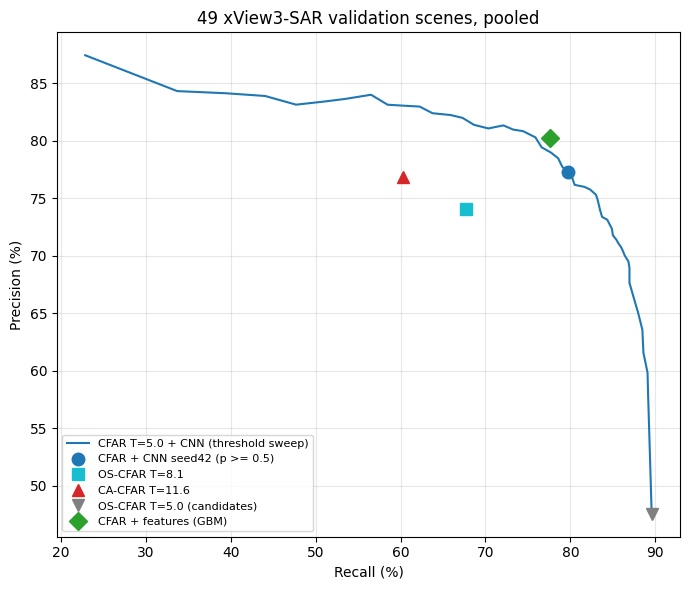

In [14]:
# Precision-recall curve of the two-stage system over CNN thresholds (secondary; its best point is optimistic).
import matplotlib.pyplot as plt
ths = np.round(np.arange(0.0, 1.0, 0.02), 2)
cand_pts = {sid: idx.loc[idx["scene_id"] == sid, ["row", "col"]].values for sid in SCENES}
cand_p = {sid: OOF[42][idx["scene_id"].values == sid] for sid in SCENES}
curve_rows = []
for t in ths:
    tp = fp = fn = 0
    for sid in SCENES:
        r = evaluate_predictions(cand_pts[sid][cand_p[sid] >= t], GT[sid]["gt_all"], GT[sid]["ig_all"], MD)
        tp += r[0]; fp += r[1]; fn += r[2]
    curve_rows.append({"threshold": t, "precision": tp / (tp + fp) if tp + fp else 1.0, "recall": tp / (tp + fn), "f1": f1_from(tp, fp, fn)})
curve_df = pd.DataFrame(curve_rows); curve_df.to_csv(os.path.join(OUT_DIR, "pr_curve_seed42.csv"), index=False)
b = curve_df.loc[curve_df["f1"].idxmax()]
print(f"Best threshold on this curve: {b['threshold']:.2f} (F1 {b['f1']*100:.1f}%, optimistic: chosen on the test predictions)")

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(curve_df["recall"] * 100, curve_df["precision"] * 100, "-", color="tab:blue", label="CFAR T=5.0 + CNN (threshold sweep)")
for n, m, col in [(PRIMARY, "o", "tab:blue"), ("OS-CFAR T=8.1", "s", "tab:cyan"), ("CA-CFAR T=11.6", "^", "tab:red"),
                  ("OS-CFAR T=5.0 (candidates)", "v", "gray"), ("CFAR + features (GBM)", "D", "tab:green")]:
    _, _, _, pr, rc, _ = pooled(n)
    ax.plot(rc * 100, pr * 100, m, color=col, ms=9, label=n + (" (p >= 0.5)" if n == PRIMARY else ""))
ax.set_xlabel("Recall (%)"); ax.set_ylabel("Precision (%)"); ax.set_title(f"{len(SCENES)} xView3-SAR validation scenes, pooled")
ax.grid(alpha=0.3); ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.savefig("cnn_pr_curve.png", dpi=150); plt.savefig(os.path.join(OUT_DIR, "cnn_pr_curve.png"), dpi=150); plt.show()
